# 2Gyr Escaped Asteroid Analysis mc_pm6_3 
The run_log_analysis python script summarises the hdf5 log files into an escaped_asteroids pandas DataFrame. This DataFrame has details of the parameter and time that the asteroid exceeds the various parameters that are monitored. 

In [1]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

xlabel_time = 'Years after start of simulation [$10^9 ~ yr$]'

In [57]:
# Read the escaped asteroids file
ea_mvc3 = pd.read_hdf('../../asteroid_data/mc_pm6_3/escaped_asteroids.h5')

In [58]:
# Strip the spaces out of the names of the asteroids
ea_mvc3['ast_name'] = [x.replace(' ','') for x in ea_mvc3.ast_name]
# Set the asteroid name as the index
ea_mvc3.set_index('ast_name', inplace=True)
ea_mvc3.describe()

,particle_number,parameter,parameter_value,integration_year
count,30048.000000,30048.000000,30048.000000,3.004800e+04
mean,9.187400,6.727070,2.485754,3.638798e+09
std,0.829406,0.750427,5.778184,3.697159e+09
min,8.000000,6.000000,-2.071092,1.000000e+04
25%,8.000000,6.000000,0.340750,4.807210e+08
50%,9.000000,7.000000,0.393673,2.135875e+09
75%,10.000000,7.000000,0.795148,6.330942e+09
max,10.000000,8.000000,98.535587,1.256510e+10


In [29]:
sim_particles= ea_mvc3[['sim_no','particle_number']].drop_duplicates()

sim_groups = sim_particles.groupby('sim_no').agg(Count_Sim = ('sim_no','count')).apply(lambda x: x==3)

dont_run = sim_groups[sim_groups.Count_Sim].index.values

print(ea_mvc3[ea_mvc3.sim_no=='06587'])

                         vectors sim_no  particle_number  parameter   
ast_name                                                              
2014OK286  XcpYcmZcpVXcmVYcmVZcp  06587                9          6  \
2007AP37   XcpYcmZcpVXcmVYcmVZcp  06587               10          6   
226572     XcpYcmZcpVXcmVYcmVZcp  06587                8          7   
2014OK286  XcpYcmZcpVXcmVYcmVZcp  06587                9          7   
226572     XcpYcmZcpVXcmVYcmVZcp  06587                8          8   
2014OK286  XcpYcmZcpVXcmVYcmVZcp  06587                9          8   

           parameter_value  integration_year  
ast_name                                      
2014OK286         4.953185      1.132351e+09  
2007AP37          0.000000      1.132980e+09  
226572            0.349269      2.601505e+09  
2014OK286         0.344588      3.267678e+08  
226572            0.558164      2.598363e+09  
2014OK286         0.614146      1.114757e+09  


In [31]:
print(f"Mars/Ceres Mercurious escaped test-particles:{(ea_mvc3.index+ea_mvc3['vectors']).nunique()}")



Mars/Ceres Mercurious escaped test-particles:16435


In [32]:
ea_mvc3.sort_values(by=['ast_name', 'vectors']).head(20)

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
ast_name,,,,,,
104287,XYZVXVYVZ,02469,8,6,4.815804,5.774826e+09
104287,XYZVXVYVZ,02469,8,7,0.359443,5.133878e+09
104287,XYZVXVYVZ,02469,8,8,0.550722,5.723927e+09
104287,XcmYcmZcmVXcmVYcpVZcp,02465,8,6,4.332087,1.118644e+10
104287,XcmYcmZcmVXcmVYcpVZcp,02465,8,7,0.356368,1.115188e+10
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,6,15.901978,2.952769e+09
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,7,0.390441,2.910668e+09
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,8,0.555398,2.930148e+09
104287,XcmYcpZcmVXcmVYcmVZcp,02451,8,6,7.351331,8.880281e+09


In [33]:
print(ea_mvc3.groupby(['parameter']).max())
print(ea_mvc3.groupby(['parameter']).min())

                         vectors sim_no  particle_number  parameter_value   
parameter                                                                   
6          XcpYcpZcpVXcpVYcpVZcp  19043               10        98.535587  \
7          XcpYcpZcpVXcpVYcpVZcp  19043               10         0.935531   
8          XcpYcpZcpVXcpVYcpVZcp  19043               10         2.945399   

           integration_year  
parameter                    
6              1.256510e+10  
7              1.255442e+10  
8              1.256510e+10  
             vectors sim_no  particle_number  parameter_value   
parameter                                                       
6          XYZVXVYVZ  00005                8        -2.071092  \
7          XYZVXVYVZ  00005                8         0.340001   
8          XYZVXVYVZ  00005                8         0.550010   

           integration_year  
parameter                    
6                   10000.0  
7                   10000.0  
8                 

In [34]:
ea_mvc3.groupby(['ast_name']).head()

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
ast_name,,,,,,
16794,XcpYcmZcpVXcpVYcmVZcp,00148,8,6,4.118940,6.208498e+08
499395,XcpYcmZcpVXcpVYcmVZcp,00148,9,6,0.000000,6.214782e+08
2002FL44,XcpYcmZcpVXcpVYcmVZcp,00148,10,6,7.460342,5.435590e+08
16794,XcpYcmZcpVXcpVYcmVZcp,00148,8,7,0.429269,5.957146e+08
2002FL44,XcpYcmZcpVXcpVYcmVZcp,00148,10,7,0.448423,4.964305e+08
...,...,...,...,...,...,...
2015NY29,XcmYcmZcmVXcpVYcpVZcm,10912,9,6,12.040188,1.212335e+10
2009SF72,XcmYcmZcmVXcpVYcpVZcm,10912,10,6,0.000000,1.212398e+10
2015NY29,XcmYcmZcmVXcpVYcpVZcm,10912,9,7,0.350449,7.928913e+09


In [35]:
escapee_years = ea_mvc3.loc[ea_mvc3.parameter == 6][['vectors', 'integration_year']]
escapee_years['integration_year'] = escapee_years.integration_year/(2*np.pi)
escapee_years

,vectors,integration_year
ast_name,,
16794,XcpYcmZcpVXcpVYcmVZcp,9.881132e+07
499395,XcpYcmZcpVXcpVYcmVZcp,9.891133e+07
2002FL44,XcpYcmZcpVXcpVYcmVZcp,8.651010e+07
499395,XcmYcpZcmVXcmVYcpVZcp,1.802193e+08
2002FL44,XcmYcpZcmVXcmVYcpVZcp,2.360391e+07
...,...,...
2009SN2,XcpYcpZcmVXcmVYcmVZcm,2.755287e+08
2015PC254,XcpYcmZcmVXcpVYcmVZcm,1.558169e+08
2009SN2,XcpYcmZcmVXcpVYcmVZcm,1.559169e+08


Text(0.5, 0, 'Years after start of simulation [$10^9 ~ yr$]')

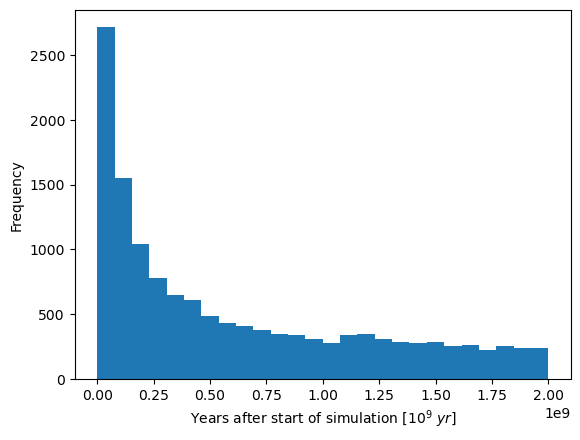

In [36]:
plt.hist(escapee_years.integration_year, bins='auto')
plt.ylabel('Frequency')
plt.xlabel(xlabel_time)

In [59]:
path = '../../asteroid_data/luthera_family.h5'
luth_fam = pd.read_hdf(path)
luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])
mag_h = 17
p_v = 0.0387
luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
print(luth_fam.head())

  ast_name  abs_mag       a_P       e_P   sineI_P family_id      irad   
0     1303     9.48  3.219248  0.121842  0.322276      1303  0.328133  \
1    11911    11.80  3.210027  0.132169  0.330567      1303  0.336904   
2    16794    13.45  3.229767  0.120773  0.321221      1303  0.327019   
3    17840    12.46  3.227073  0.122213  0.322861      1303  0.328751   
4    26558    13.15  3.194646  0.115763  0.319342      1303  0.325035   

        ideg       diam  
0  18.800624  85.836005  
1  19.303194  29.489642  
2  18.736782  13.793342  
3  18.836035  21.760531  
4  18.623137  15.836875  


In [60]:
luth_fam = luth_fam.set_index('ast_name')

In [49]:
escaped_asts = ea_mvc3.index.unique()

print(len(escaped_asts),escaped_asts)

596 Index(['16794', '499395', '2002FL44', '33292', '505088', '2002PX190',
       '2002NO62', '17840', '2002GM31', '500005',
       ...
       '321506', '2015PC254', '2009SN2', '325386', '2009SV410', '2009SU10',
       '2015PD48', '2015PE4', '2015NY29', '2009SF72'],
      dtype='object', name='ast_name', length=596)


In [50]:
luth_fam[luth_fam.index.isin(escaped_asts)==True]

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam,integration_year,quartiles,graph_symbol
ast_name,,,,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,1303,0.328133,18.800624,85.836005,1.847983e+09,1.0,o
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342,7.597187e+08,2.0,o
17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531,1.299537e+09,1.0,o
33292,12.99,3.227360,0.129485,0.326713,1303,0.332824,19.069389,17.047845,1.331040e+09,1.0,o
44492,13.69,3.220273,0.123425,0.324298,1303,0.330270,18.923050,12.350072,1.368174e+09,1.0,o
...,...,...,...,...,...,...,...,...,...,...,...
2013BN95,17.17,3.194082,0.114092,0.317706,1303,0.323309,18.524250,2.486964,1.584983e+09,1.0,o
2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399,3.244352e+08,4.0,o
2013CG92,17.20,3.194881,0.135663,0.334094,1303,0.340644,19.517454,2.452842,9.134665e+08,2.0,o


In [61]:
luth_fam[luth_fam.index.isin(('2010VV146','2017AC51'))==True]

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
ast_name,,,,,,,,
2010VV146,17.41,3.17278,0.120229,0.32158,1303,0.327398,18.758504,2.22674


In [62]:
ey_years = escapee_years.groupby(by=escapee_years.index)
mean_escape = ey_years.mean('integration_year')

mean_escape['vec_count'] = ey_years.vectors.count()

escapee_years.sort_values('integration_year')
luth_fam[luth_fam.index.isin(escapee_years.index)==True]

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
ast_name,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,1303,0.328133,18.800624,85.836005
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531
33292,12.99,3.227360,0.129485,0.326713,1303,0.332824,19.069389,17.047845
44492,13.69,3.220273,0.123425,0.324298,1303,0.330270,18.923050,12.350072
...,...,...,...,...,...,...,...,...
2013BN95,17.17,3.194082,0.114092,0.317706,1303,0.323309,18.524250,2.486964
2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399
2013CG92,17.20,3.194881,0.135663,0.334094,1303,0.340644,19.517454,2.452842


In [63]:
counts, bins = np.histogram(mean_escape.vec_count, 4)
mean_escape['quartiles'] = np.digitize(mean_escape.vec_count, bins)

In [64]:
luth_fam['integration_year'] = mean_escape.integration_year
luth_fam['quartiles'] = mean_escape.quartiles

luth_fam = luth_fam.fillna(value={'integration_year': 0, 'vec_count': 0})
luth_fam['graph_symbol'] = '.'
luth_fam.loc[luth_fam['integration_year']!=0,['graph_symbol']] = 'o'
len(luth_fam[luth_fam['integration_year']!=0])

573

In [65]:
def flash_plot(ax, ast_data, y_column, x_column='a_P'):
    for graph_symbol, m_fam in ast_data.groupby('graph_symbol'):
        if graph_symbol == '.':
            stab = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='white', marker='P', 
            c='black', label='Stable Asteroid')
        else:
            cm_yr = mpl.colormaps['inferno'] 
            norm_vecs = m_fam['quartiles']*40
            colour_values = m_fam['integration_year']
            esc = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='black', marker=graph_symbol, 
                c=colour_values, cmap = cm_yr, s=norm_vecs, label='Quartile')
                
            cb = plt.colorbar(esc, label=xlabel_time, location='bottom')
    
    esc_elements = esc.legend_elements("sizes", num=4)
    stab_elements = stab.legend_elements("sizes", num=1)
        
    plt.legend(handles = stab_elements[0] + esc_elements[0], 
               labels=['Stable', '<25% Clones', '25-50% Clones','51-75% Clones', '>75% Clones'],
               bbox_to_anchor=(1.0, 1.0))


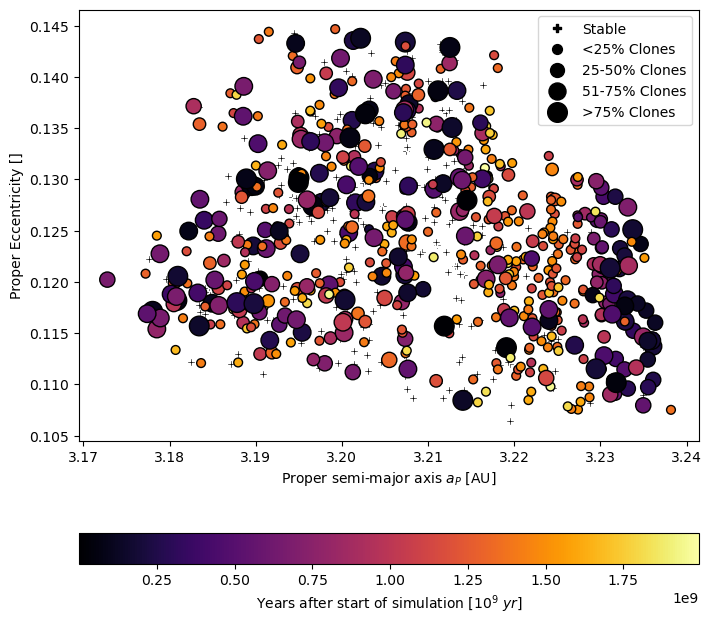

In [66]:
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'e_P')

plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.show()

In [67]:
luth_fam[luth_fam.a_P <= 3.175]

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam,integration_year,quartiles,graph_symbol
ast_name,,,,,,,,,,,
2010VV146,17.41,3.17278,0.120229,0.32158,1303,0.327398,18.758504,2.22674,6.661814e+08,3.0,o


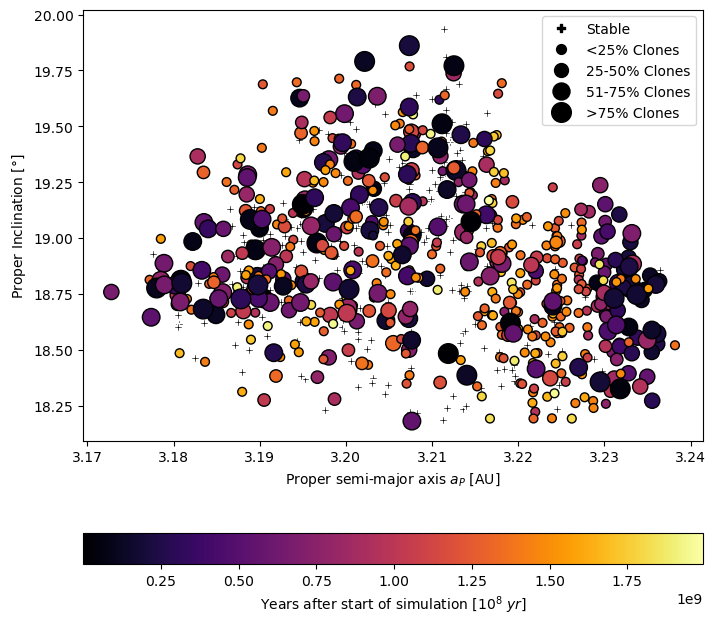

In [22]:
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ideg')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.show()

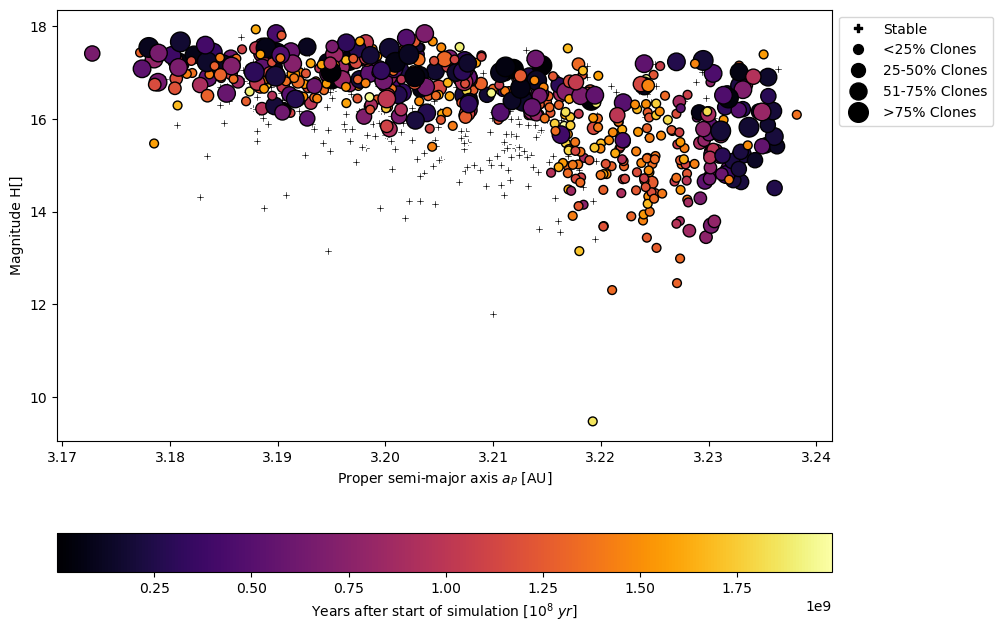

In [23]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'abs_mag')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Magnitude H[]")
plt.show()

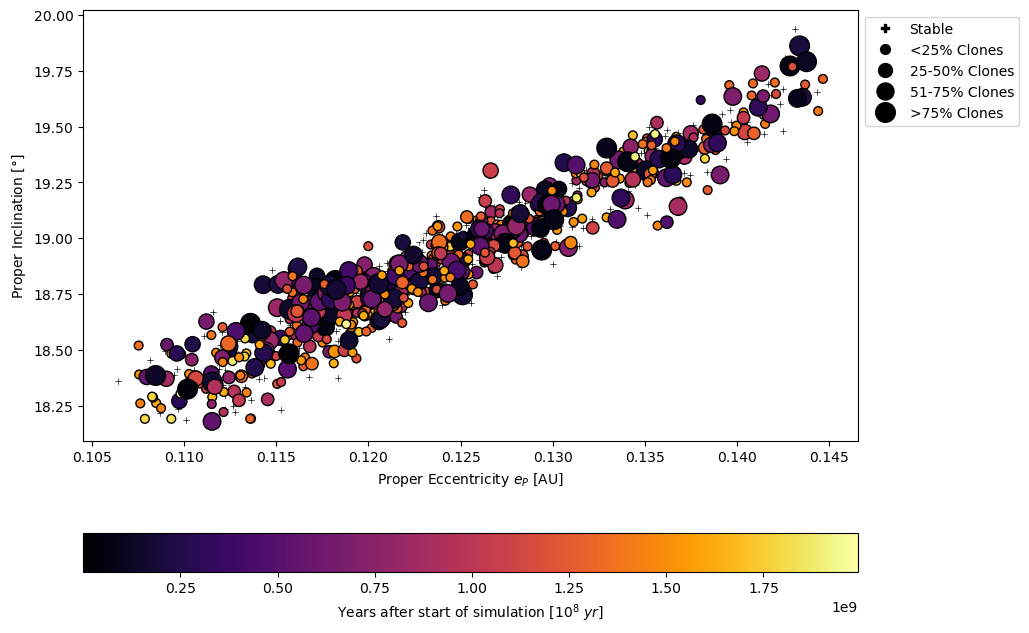

In [24]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ideg', 'e_P')
    
plt.xlabel("Proper Eccentricity $e_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.show()

In [25]:
def hist_ratio(data, col_name, x_label):
    stable_cnts, bins = np.histogram(data[data.integration_year == 0][col_name],bins='auto')  
    escp_cnts, bins = np.histogram(data[data.integration_year != 0][col_name],bins=bins)
    ratio = ((stable_cnts)/(stable_cnts+escp_cnts+1.0e-40))*100

    fig = plt.figure(figsize=(8, 8))
    ax0 = plt.subplot(111)
    ax1 = ax0.twinx()
    ax0.hist([data[data.integration_year == 0][col_name], 
                  data[data.integration_year != 0][col_name]], bins=bins, stacked=True)
    ax0.set_ylabel("Frequency")
    ax0.set_xlabel(x_label)
    ax0.legend(labels=['Stable', 'Escaped'])


    ax1.plot(bins[:-1]+(bins[1]-bins[0])/2,ratio, c='grey', marker='+')
    ax1.set_ylim(0,100)
    ax1.set_ylabel("Asteroid Stability [%]")
    plt.show()
    

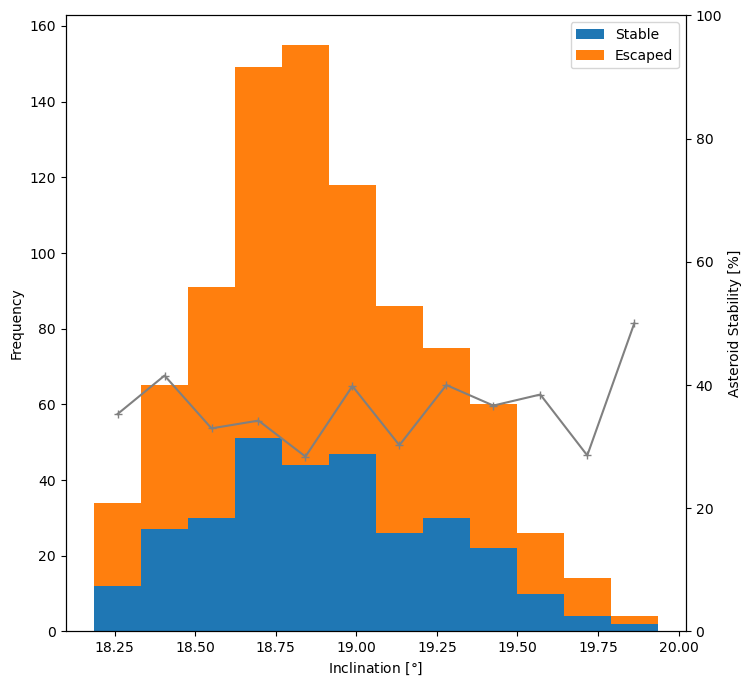

In [26]:
hist_ratio(luth_fam, 'ideg', "Inclination [$\degree$]")

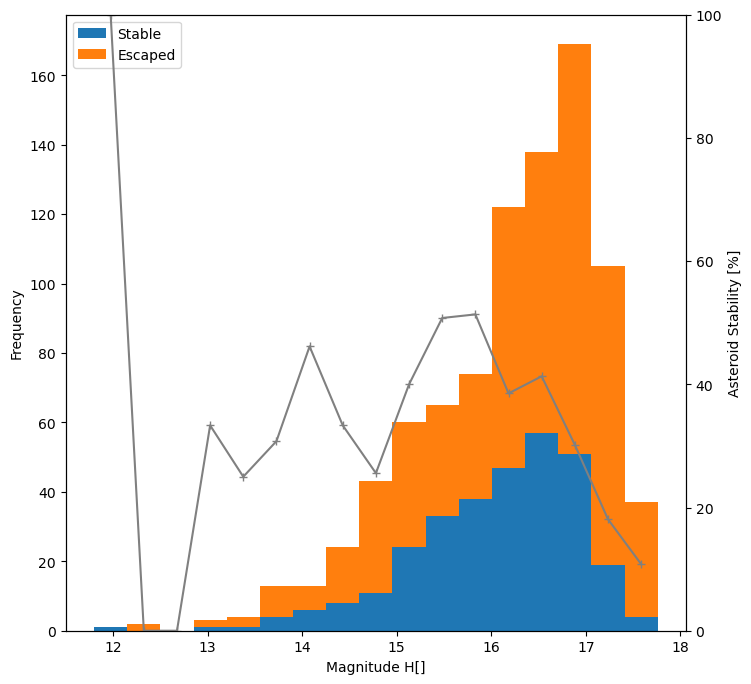

In [27]:
hist_ratio(luth_fam, 'abs_mag', "Magnitude H[]")

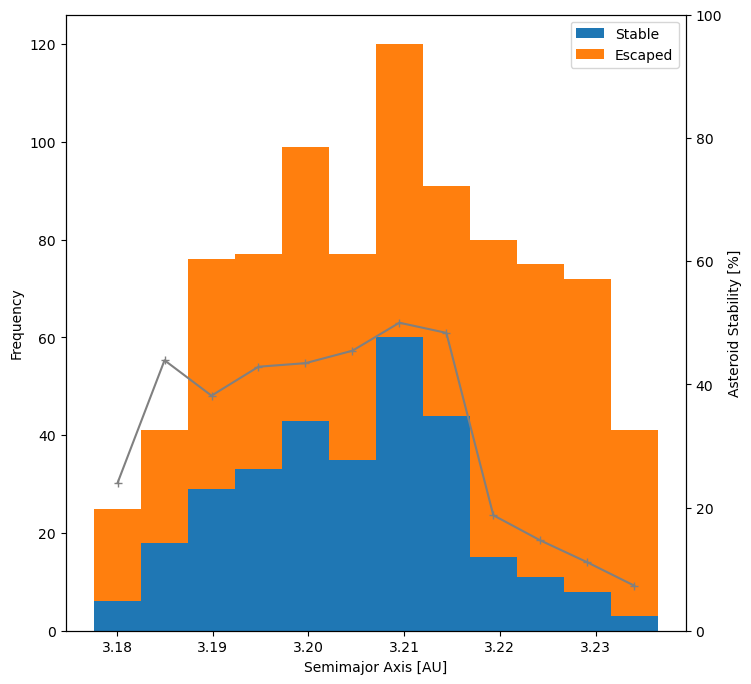

In [28]:
hist_ratio(luth_fam, 'a_P', "Semimajor Axis [AU]")

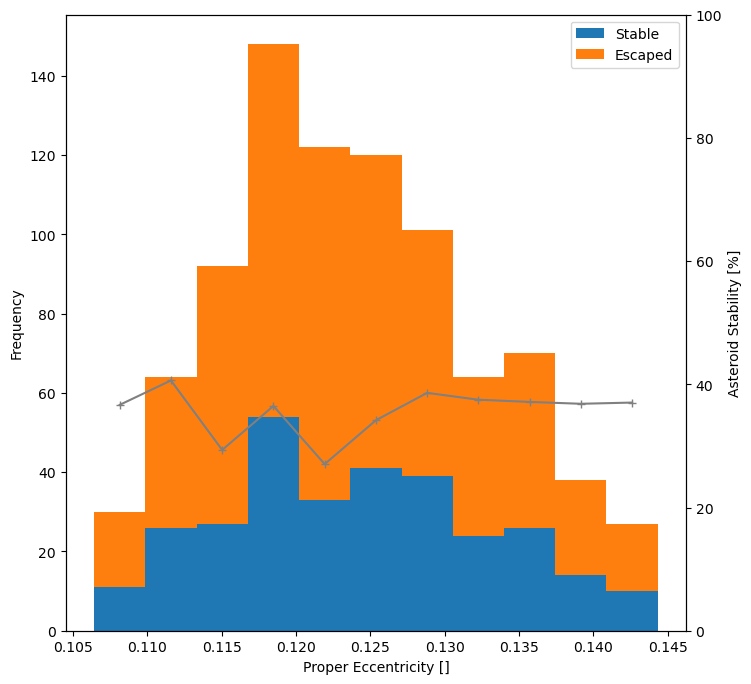

In [29]:
hist_ratio(luth_fam, 'e_P', "Proper Eccentricity []")